In [1]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [3]:
import os

DATASET_PATH = "/kaggle/input/datasets"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)
    indent = "  " * level

    print(f"{indent}{os.path.basename(root)}/")

    if level < 3:
        for file in files[:10]:
            print(f"{indent}  {file}")

datasets/
  safanasri002/
    dataset/
      dataset/
        physionet/
          training-a/
          training-e/
          training-b/
          training-f/
          training-d/
          training-c/
        pascal/
          extra/
          normal/
          murmur/


In [4]:
# Chemin du dataset Kaggle (lecture seule)
DATASET_PATH = "/kaggle/input/datasets/safanasri002/dataset/dataset"

# Dossier de travail Kaggle (lecture + écriture)
WORKING_PATH = "/kaggle/working"

print("Dataset :", DATASET_PATH)
print("PhysioNet :", DATASET_PATH + "/physionet")
print("Pascal :", DATASET_PATH + "/pascal")

Dataset : /kaggle/input/datasets/safanasri002/dataset/dataset
PhysioNet : /kaggle/input/datasets/safanasri002/dataset/dataset/physionet
Pascal : /kaggle/input/datasets/safanasri002/dataset/dataset/pascal


In [6]:
folder_to_copy = "datasets/ourdataset/train/"

In [7]:
import os

TRAIN_PATH = "/kaggle/working/ourdataset/train"

os.makedirs(TRAIN_PATH + "/normal", exist_ok=True)
os.makedirs(TRAIN_PATH + "/abnormal", exist_ok=True)

print("Normal :", TRAIN_PATH + "/normal")
print("Abnormal :", TRAIN_PATH + "/abnormal")

Normal : /kaggle/working/ourdataset/train/normal
Abnormal : /kaggle/working/ourdataset/train/abnormal


In [8]:
import os

physionet_path = DATASET_PATH + "/physionet"

print(os.listdir(physionet_path))

['training-a', 'training-e', 'training-b', 'training-f', 'training-d', 'training-c']


In [9]:
print(
    os.listdir(physionet_path + "/training-a")[:10]
)

['a0032.wav', 'a0343.hea', 'a0031.dat', 'a0142.wav', 'a0393.hea', 'a0321.dat', 'a0360.hea', 'a0254.hea', 'a0211.wav', 'a0409.wav']


In [10]:
def readFromPhysionet_CSV():
    root_folder_to_read = DATASET_PATH + "/physionet/"
    folder_to_copy = TRAIN_PATH + "/"
    folders = ["training-a", "training-b", "training-c", "training-d", "training-e", "training-f"]
    for folder in folders:
        csvfilename = root_folder_to_read + folder + "/REFERENCE.csv"
        folder_to_read = root_folder_to_read + folder
        with open(csvfilename, "r") as csvDataFile:
            data = [row for row in csv.reader(csvDataFile)]
            for row in data:
                wav_name = row[0]
                wav_type = row[1]
                file_source = folder_to_read + "/" + wav_name + ".wav"
                # -1 : normal, 1 : abnormal
                if int(wav_type) == -1:
                    shutil.copy(file_source, folder_to_copy + "normal")
                elif int(wav_type) == 1:
                    shutil.copy(file_source, folder_to_copy + "abnormal")
        print(folder, "OK")

readFromPhysionet_CSV()
print("normal  :", len(os.listdir(TRAIN_PATH + "/normal")))
print("abnormal:", len(os.listdir(TRAIN_PATH + "/abnormal")))

NameError: name 'csv' is not defined

In [29]:
def readFromPascal():
    source = DATASET_PATH + "/pascal/"
    destination = TRAIN_PATH + "/"
    folders = ["normal", "extra", "murmur"]
    for folder in folders:
        wavs = glob(source + folder + "/*.wav")
        classe = "normal" if folder == "normal" else "abnormal"
        for wav in wavs:
            file_name = os.path.basename(wav)
            shutil.copy(wav, destination + classe + "/" + file_name)
        print(folder, ":", len(wavs), "fichiers ->", classe)

readFromPascal()
print("normal  :", len(os.listdir(TRAIN_PATH + "/normal")))
print("abnormal:", len(os.listdir(TRAIN_PATH + "/abnormal")))

normal : 351 fichiers -> normal
extra : 65 fichiers -> abnormal
murmur : 129 fichiers -> abnormal
normal  : 2926
abnormal: 858


In [30]:
import soundfile as sf

def get_wav_duration(name):
    wavs_duration = []
    for _wav in sorted(os.listdir(name)):
        if ".wav" in _wav:
            file = name + _wav
            try:
                duration = sf.info(file).duration
            except Exception:
                data, rate = librosa.load(file, sr=None)
                duration = librosa.get_duration(y=data, sr=rate)
            wavs_duration.append(duration)
    return wavs_duration

def getDuration(folder, file_name):
    for type in ["normal", "abnormal"]:
        wavs_duration = get_wav_duration(folder + type + "/")
        pickle.dump(wavs_duration, open(folder + 'wavs_duration_' + type + file_name + '.data', 'wb'))
        print(type, ":", len(wavs_duration), "durées calculées")

folder = TRAIN_PATH + "/"
file_name = "_train"
getDuration(folder, file_name)

normal : 2926 durées calculées
abnormal : 858 durées calculées


Duration... normal


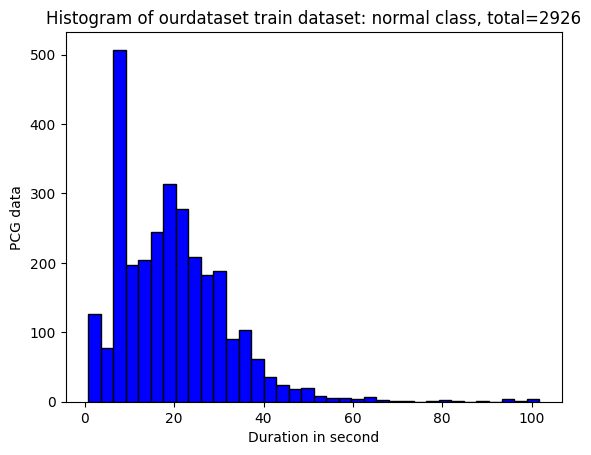

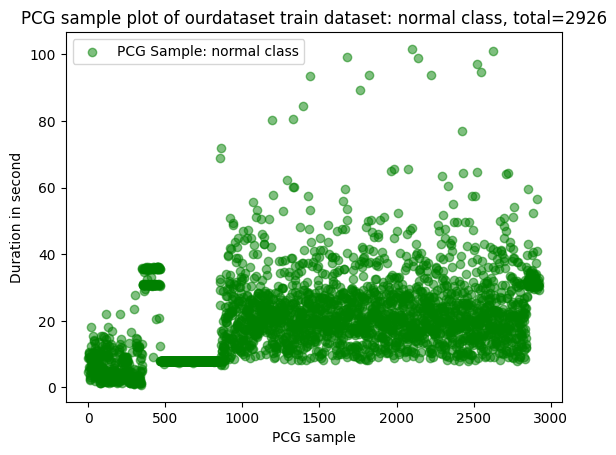

Duration... abnormal


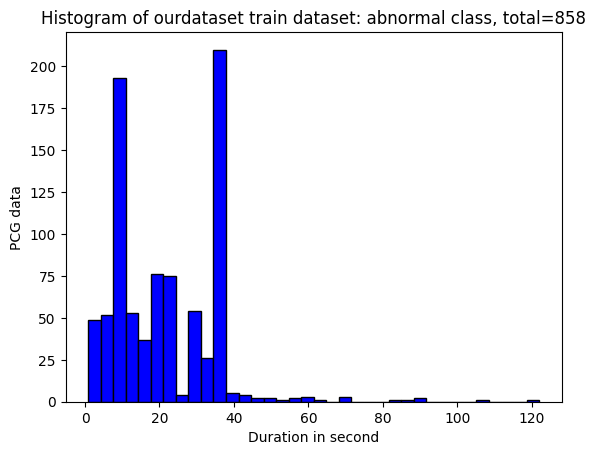

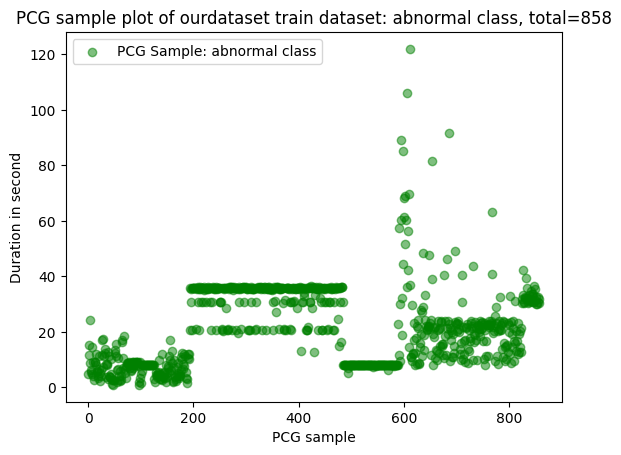

In [31]:
def getHIST(data, type, dataset_type, x_txt, y_txt):
    plt.hist(data, color='blue', edgecolor='black', bins=int(180/binwidth))
    plt.title('Histogram of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel(y_txt)
    plt.show()

def PlotScatter(data, type, color_type, dataset_type, x_txt, y_txt):
    plt.scatter(np.arange(len(data)), data, alpha=0.5, color=color_type,
                label="PCG Sample: " + type + " class")
    plt.title('PCG sample plot of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt)
    plt.ylabel(y_txt)
    plt.legend()
    plt.show()

types = ["normal", "abnormal"]
dataset_type = "train"
binwidth = 5
for type in types:
    wavs_duration_data = pickle.load(open(folder + 'wavs_duration_' + type + file_name + '.data', 'rb'))
    print("Duration...", type)
    getHIST(wavs_duration_data, type, dataset_type, 'Duration in second', 'PCG data')
    PlotScatter(wavs_duration_data, type, "green", dataset_type, "PCG sample", "Duration in second")

In [32]:
for type in types:
    d = np.array(pickle.load(open(folder + 'wavs_duration_' + type + file_name + '.data', 'rb')))
    print(f"{type:9s} n={len(d):5d}  moyenne={d.mean():.1f}s  min={d.min():.1f}s  max={d.max():.1f}s")

normal    n= 2926  moyenne=19.8s  min=0.8s  max=101.7s
abnormal  n=  858  moyenne=21.5s  min=0.9s  max=122.0s


In [33]:
import numpy as np

a = np.array([[1, 2], [3, 4]])   # matrice 2x2
print(np.std(a))                 # écart-type de TOUTES les valeurs → 1.118
print(np.std(a, axis=0))         # écart-type par COLONNE → [1. 1.]
print(np.std(a, axis=1))         # écart-type par LIGNE   → [0.5 0.5]

1.118033988749895
[1. 1.]
[0.5 0.5]


In [34]:
import os
import pickle
import numpy as np
import librosa
import librosa.display            # pour afficher les spectrogrammes
import matplotlib.pyplot as plt
import seaborn as sns

TRAIN_PATH = "/kaggle/working/ourdataset/train"   # dossier créé au TP1
folder = TRAIN_PATH + "/"
file_name = "_train"

print(os.listdir(folder))

['abnormal', 'wavs_duration_normal_train.data', 'wavs_duration_abnormal_train.data', 'normal']


In [35]:
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)                     # convertit en tableau numpy
    m = a.mean(axis)                         # moyenne du signal
    sd = a.std(axis=axis, ddof=ddof)         # écart-type du signal
    return np.where(sd == 0, 0, m / sd)      # SNR = moyenne / écart-type (0 si écart-type nul)

def snr(name):
    snr_data = []                            # liste des SNR de la classe
    for _wav in sorted(os.listdir(name)):    # tous les fichiers du dossier
        if ".wav" in _wav:
            file = name + "/" + _wav
            data, rate = librosa.load(file, sr=None)   # charge le signal à sa fréquence d'origine
            singleChannel = data
            if data.ndim > 1:                          # si stéréo → on additionne les canaux
                singleChannel = np.sum(data, axis=0)
            # normalisation : on divise par la plus grande amplitude (en valeur absolue) → signal entre -1 et 1
            norm = singleChannel / max(np.amax(singleChannel), -1 * np.amin(singleChannel))
            res = signaltonoise(norm)                  # SNR du signal normalisé
            snr_data.append(float(res))
    return snr_data

def getSNR(folder, file_name):
    for type in ["normal", "abnormal"]:
        snr_data = snr(folder + type)
        pickle.dump(snr_data, open(folder + 'snr_' + type + file_name + '.data', 'wb'))  # sauvegarde
        print(type, ":", len(snr_data), "SNR calculés")

getSNR(folder, file_name)

normal : 2926 SNR calculés
abnormal : 858 SNR calculés


In [37]:
def getHIST(data, type, dataset_type, x_txt, y_txt):
    plt.hist(data, color='blue', edgecolor='black', bins=int(180/binwidth))  # histogramme, 36 barres
    plt.title('Histogram of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt); plt.ylabel(y_txt)
    plt.show()

def getHIST_KDE(data, type, dataset_type, x_txt, y_txt):
    # remplace sns.distplot(hist=True, kde=True, rug=True)
    sns.histplot(data, bins=int(180/5), stat='density', color='darkblue', edgecolor='black')  # histogramme normalisé
    sns.kdeplot(data, color='red', linewidth=3, label='KDE')     # courbe de densité lissée
    sns.rugplot(data, color='g')                                 # un petit trait par valeur sur l'axe X
    plt.title('Histogram of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt); plt.ylabel(y_txt); plt.legend()
    plt.show()

def getRug_KDE(data, type, dataset_type, x_txt, y_txt):
    # remplace sns.distplot(hist=False, kde=True, rug=True)
    sns.kdeplot(data, color='darkblue', linewidth=3, label='KDE')
    sns.rugplot(data, color='black')
    plt.title('Density plot of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt); plt.ylabel(y_txt); plt.legend()
    plt.show()

def PlotScatter(data, type, color_type, dataset_type, x_txt, y_txt):
    plt.scatter(np.arange(len(data)), data, alpha=0.5, color=color_type,
                label="PCG Sample: " + type + " class")
    plt.title('PCG sample plot of ourdataset ' + dataset_type + ' dataset: ' + type + ' class, total=' + str(len(data)))
    plt.xlabel(x_txt); plt.ylabel(y_txt); plt.legend()
    plt.show()

SNR... normal


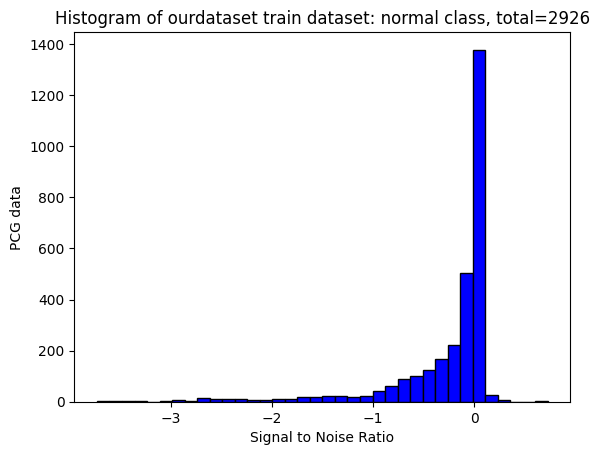

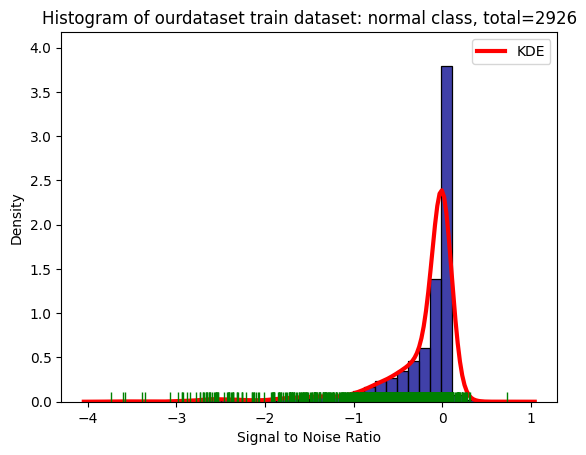

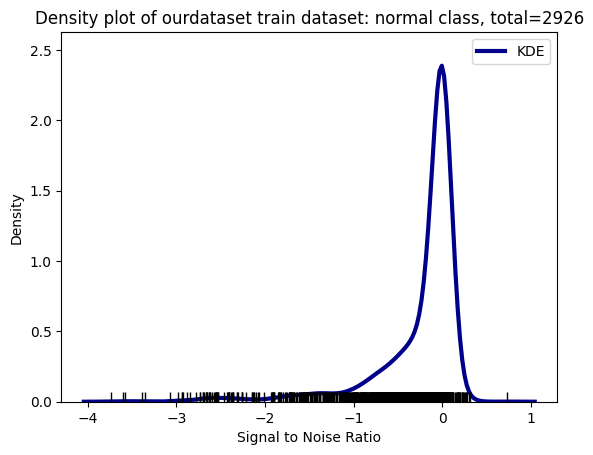

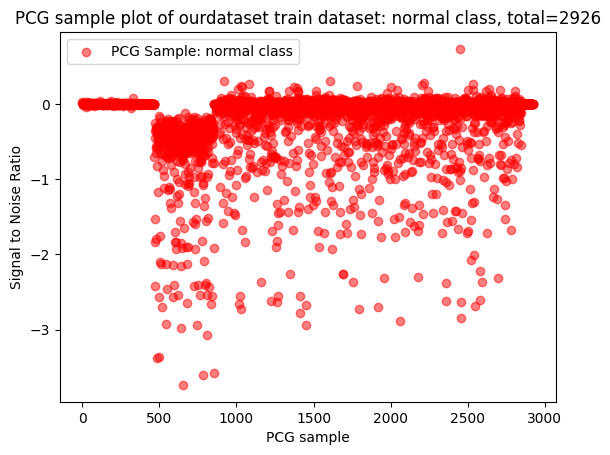

Duration... normal


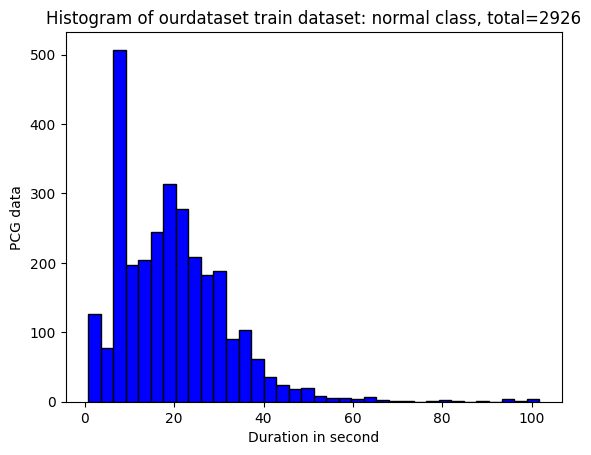

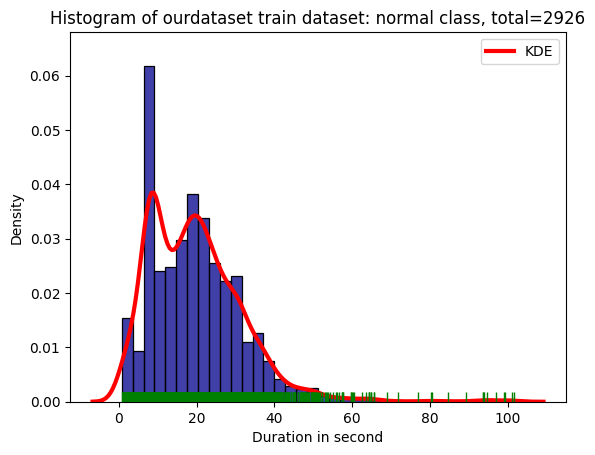

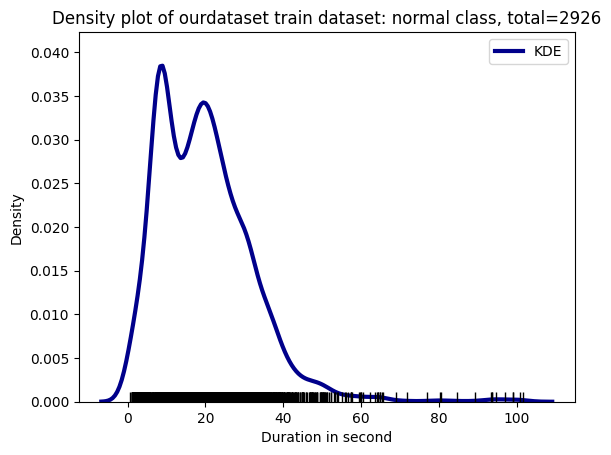

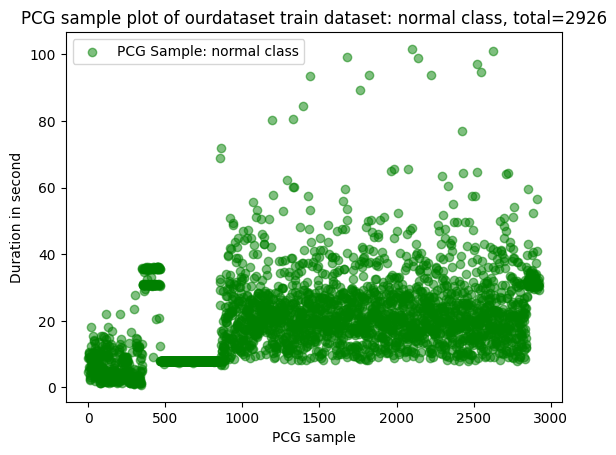

SNR... abnormal


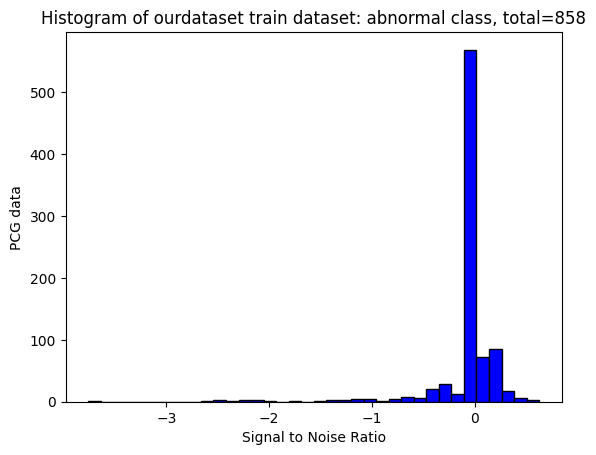

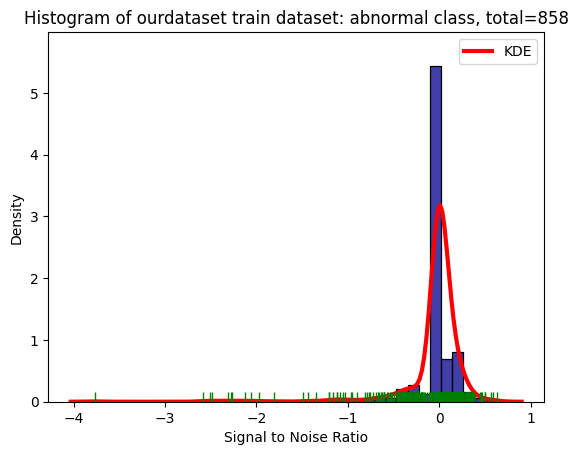

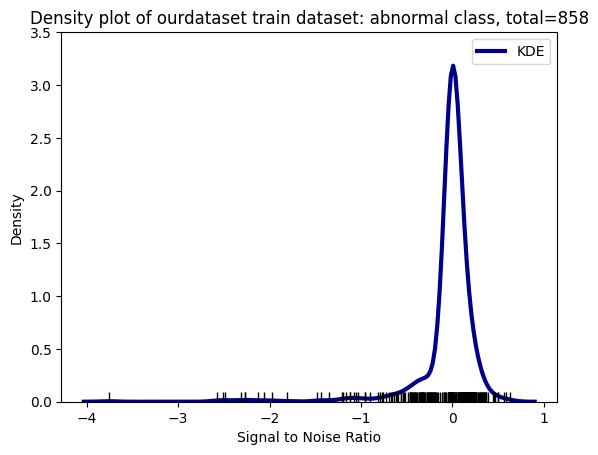

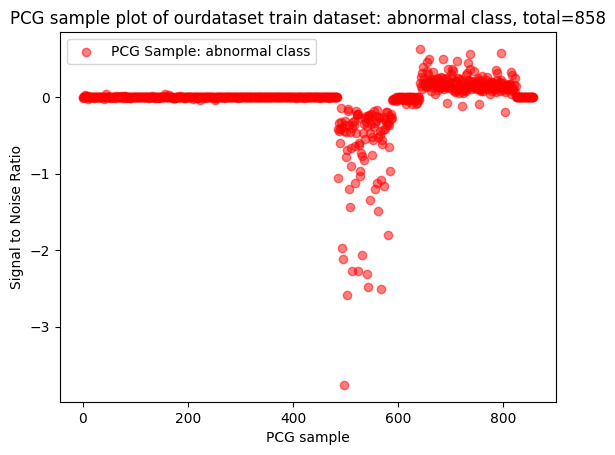

Duration... abnormal


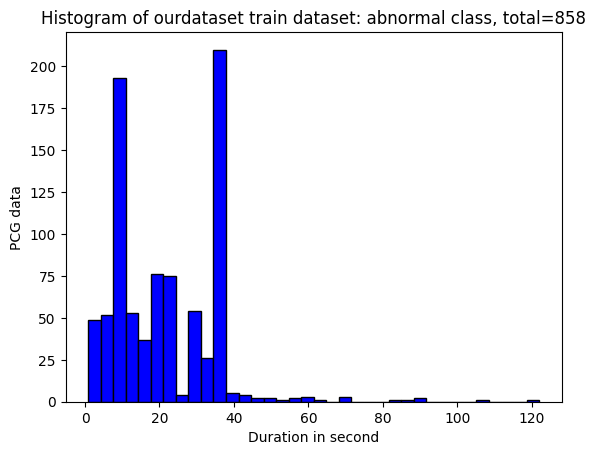

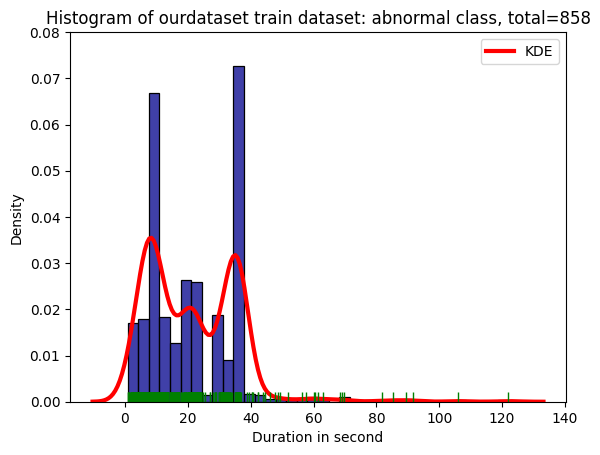

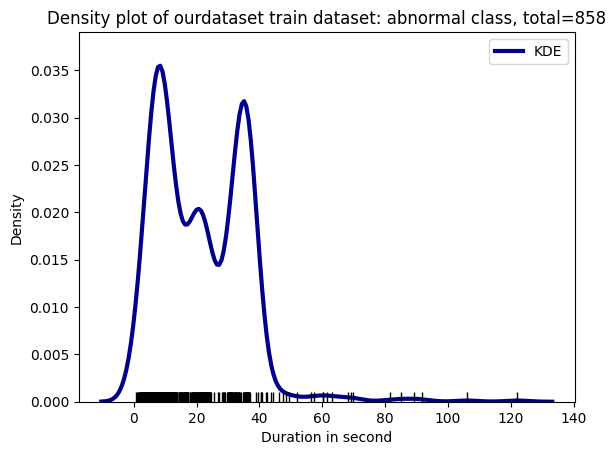

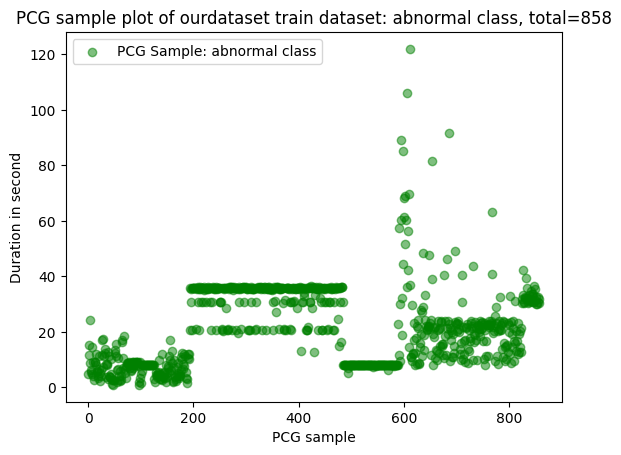

In [38]:
types = ["normal", "abnormal"]
dataset_type = "train"
binwidth = 5

for type in types:
    wavs_duration_data = pickle.load(open(folder + 'wavs_duration_' + type + file_name + '.data', 'rb'))  # du TP1
    snr_data = pickle.load(open(folder + 'snr_' + type + file_name + '.data', 'rb'))                      # cellule 3

    print("SNR...", type)
    getHIST(snr_data, type, dataset_type, 'Signal to Noise Ratio', 'PCG data')
    getHIST_KDE(snr_data, type, dataset_type, 'Signal to Noise Ratio', 'Density')
    getRug_KDE(snr_data, type, dataset_type, 'Signal to Noise Ratio', 'Density')
    PlotScatter(snr_data, type, "red", dataset_type, "PCG sample", "Signal to Noise Ratio")

    print("Duration...", type)
    getHIST(wavs_duration_data, type, dataset_type, 'Duration in second', 'PCG data')
    getHIST_KDE(wavs_duration_data, type, dataset_type, 'Duration in second', 'Density')
    getRug_KDE(wavs_duration_data, type, dataset_type, 'Duration in second', 'Density')
    PlotScatter(wavs_duration_data, type, "green", dataset_type, "PCG sample", "Duration in second")

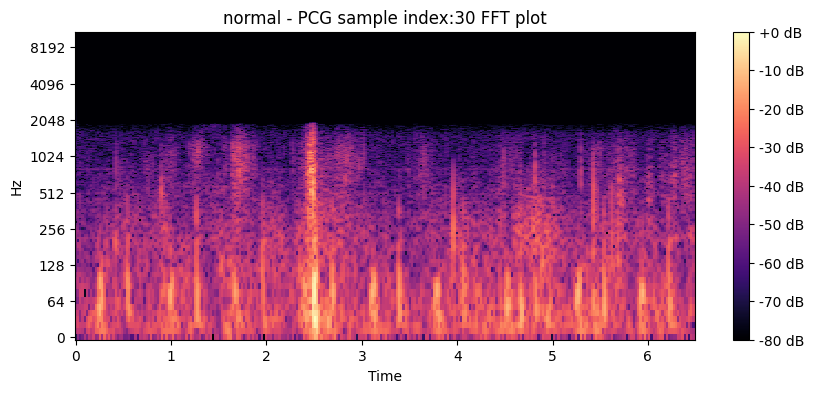

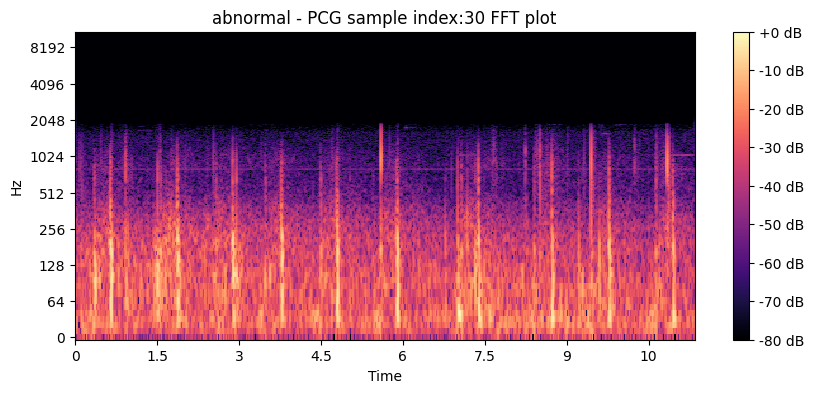

In [39]:
def plotFFT(name, index):
    _wavs = sorted(f for f in os.listdir(name) if ".wav" in f)   # liste des .wav du dossier
    file = name + _wavs[index]                                   # prend le fichier n° index
    signal, rate = librosa.load(file)                            # charge (rééchantillonné à 22 050 Hz)
    D = np.abs(librosa.stft(signal, n_fft=n_fft, hop_length=hop_length))  # STFT : FFT sur des fenêtres glissantes
    DB = librosa.amplitude_to_db(D, ref=np.max)                  # amplitude → décibels (0 dB = le max)
    plt.figure(figsize=(10, 4))                                  # nouvelle figure pour chaque classe
    librosa.display.specshow(DB, sr=rate, hop_length=hop_length, x_axis='time', y_axis='log')
    plt.colorbar(format='%+2.0f dB')                             # échelle des couleurs
    plt.title(name.split('/')[-2] + ' - PCG sample index:' + str(index) + ' FFT plot')
    plt.show()

hop_length = 512    # décalage entre deux fenêtres (en échantillons)
n_fft = 2048        # taille de chaque fenêtre FFT

for type in types:
    plotFFT(folder + type + "/", 30)

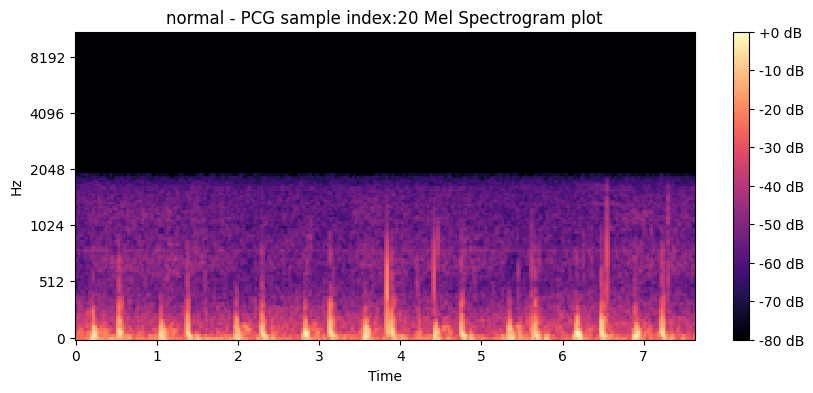

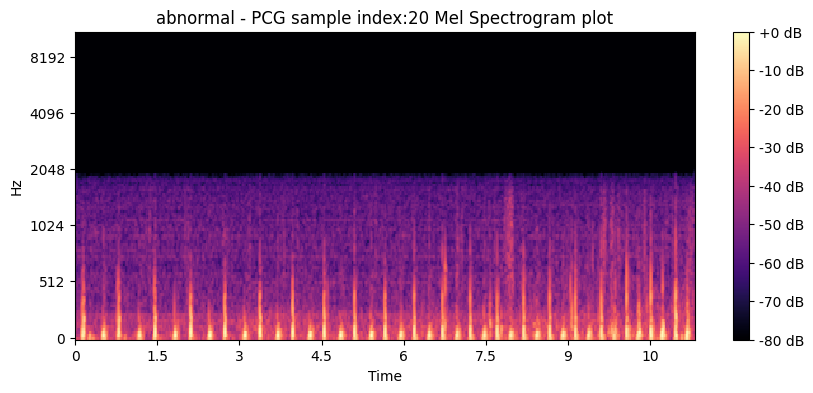

In [40]:
def plotMelSpectrogram(name, index):
    _wavs = sorted(f for f in os.listdir(name) if ".wav" in f)
    file = name + _wavs[index]
    signal, rate = librosa.load(file)
    S = librosa.feature.melspectrogram(y=signal, sr=rate, n_fft=n_fft,
                                       hop_length=hop_length, n_mels=n_mels)  # y= obligatoire avec la version actuelle de librosa
    S_DB = librosa.power_to_db(S, ref=np.max)                                 # puissance → dB
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(S_DB, sr=rate, hop_length=hop_length, x_axis='time', y_axis='mel')
    plt.colorbar(format='%+2.0f dB')
    plt.title(name.split('/')[-2] + ' - PCG sample index:' + str(index) + ' Mel Spectrogram plot')
    plt.show()

hop_length = 512
n_fft = 2048
n_mels = 128        # nombre de bandes Mel (lignes du spectrogramme)

for type in types:
    plotMelSpectrogram(folder + type + "/", 20)